# Financial Market Regimes Analysis

**Topic:** F9 – Régimes de marché  
**Task:** Unsupervised learning / clustering

The objective of this project is to identify different financial market regimes using historical market data and unsupervised machine learning techniques. We will calculate financial indicators and group market observations according to their characteristics.

## 1. Importation des bibliothèques

In [1]:
!pip -q install yfinance

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="darkgrid")
plt.rcParams["figure.figsize"] = (12, 5)

## 2. Téléchargement des données financières

In [2]:
# S&P 500 daily historical data
ticker = "^GSPC"

data = yf.download(
    ticker,
    start="2015-01-01",
    end="2026-11-17",
    auto_adjust=True,
    progress=False
)

if data.empty:
    raise ValueError(
        "Aucune donnée n'a été téléchargée. Vérifiez la connexion Internet "
        "de Colab ou réessayez plus tard."
    )

# yfinance may return MultiIndex columns depending on its version
if isinstance(data.columns, pd.MultiIndex):
    data.columns = data.columns.get_level_values(0)

required_columns = ["Close", "Volume"]
missing_columns = [col for col in required_columns if col not in data.columns]
if missing_columns:
    raise ValueError(f"Colonnes absentes dans les données : {missing_columns}")

data = data[required_columns].copy()
data = data.sort_index()
data = data[~data.index.duplicated(keep="first")]

print("Dimensions du dataset :", data.shape)
print("Période :", data.index.min().date(), "à", data.index.max().date())
display(data.head())

Dimensions du dataset : (2986, 2)
Période : 2015-01-02 à 2026-11-16


Price,Close,Volume
Date,,
2015-01-02,2058.199951,2708700000
2015-01-05,2020.579956,3799120000
2015-01-06,2002.609985,4460110000
2015-01-07,2025.900024,3805480000
2015-01-08,2062.139893,3934010000


## 3. Exploration des données

In [3]:
print("Informations générales :")
data.info()

print("\nValeurs manquantes :")
display(data.isnull().sum().to_frame("Nombre de valeurs manquantes"))

print("\nStatistiques descriptives :")
display(data.describe())

Informations générales :
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2986 entries, 2015-01-02 to 2026-11-16
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   2986 non-null   float64
 1   Volume  2986 non-null   int64  
dtypes: float64(1), int64(1)
memory usage: 70.0 KB

Valeurs manquantes :


,Nombre de valeurs manquantes
Price,
Close,0
Volume,0



Statistiques descriptives :


Price,Close,Volume
count,2986.000000,2.986000e+03
mean,3886.587522,4.204600e+09
std,1603.671267,1.057166e+09
min,1829.079956,0.000000e+00
25%,2581.017517,3.502222e+09
50%,3636.880005,3.967435e+09
75%,4701.132446,4.721582e+09
max,7818.930176,1.002582e+10


## 4. Visualisation 1 – Évolution du S&P 500

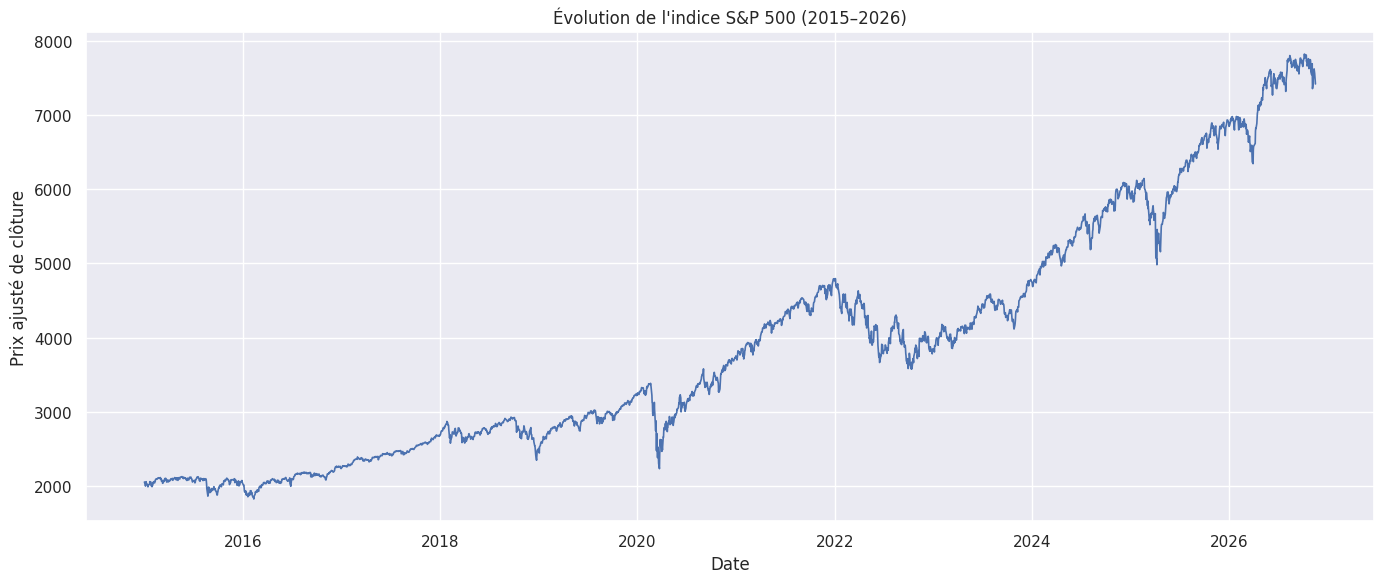

In [4]:
plt.figure(figsize=(14, 6))
plt.plot(data.index, data["Close"], linewidth=1.2)
plt.title("Évolution de l'indice S&P 500 (2015–2026)")
plt.xlabel("Date")
plt.ylabel("Prix ajusté de clôture")
plt.tight_layout()
plt.show()

Le graphique présente l'évolution historique de l'indice S&P 500. Les variations du niveau de l'indice permettent de repérer les grandes phases de hausse et de baisse du marché.

## 5. Création des indicateurs financiers

In [5]:
# Rendement journalier
data["Return"] = data["Close"].pct_change()

# Volatilité historique sur 20 séances
data["Volatility"] = data["Return"].rolling(window=20).std()

# Momentum sur 20 séances
data["Momentum"] = data["Close"].pct_change(periods=20)

# Drawdown par rapport au maximum des 20 dernières séances
rolling_max = data["Close"].rolling(window=20).max()
data["Drawdown"] = data["Close"] / rolling_max - 1

# Nettoyage des lignes générées par les fenêtres glissantes
data = data.replace([np.inf, -np.inf], np.nan).dropna()

display(data[["Close", "Return", "Volatility", "Momentum", "Drawdown"]].head())
print("Dimensions après création des indicateurs :", data.shape)

Price,Close,Return,Volatility,Momentum,Drawdown
Date,,,,,
2015-02-02,2020.849976,0.012962,0.011192,-0.018147,-0.020503
2015-02-03,2050.030029,0.014439,0.010899,0.014575,-0.006359
2015-02-04,2041.510010,-0.004156,0.010727,0.019425,-0.010489
2015-02-05,2062.520020,0.010291,0.010662,0.018076,-0.000305
2015-02-06,2055.469971,-0.003418,0.009919,-0.003234,-0.003722


Dimensions après création des indicateurs : (2966, 6)


## 6. Visualisation 2 – Rendements et volatilité

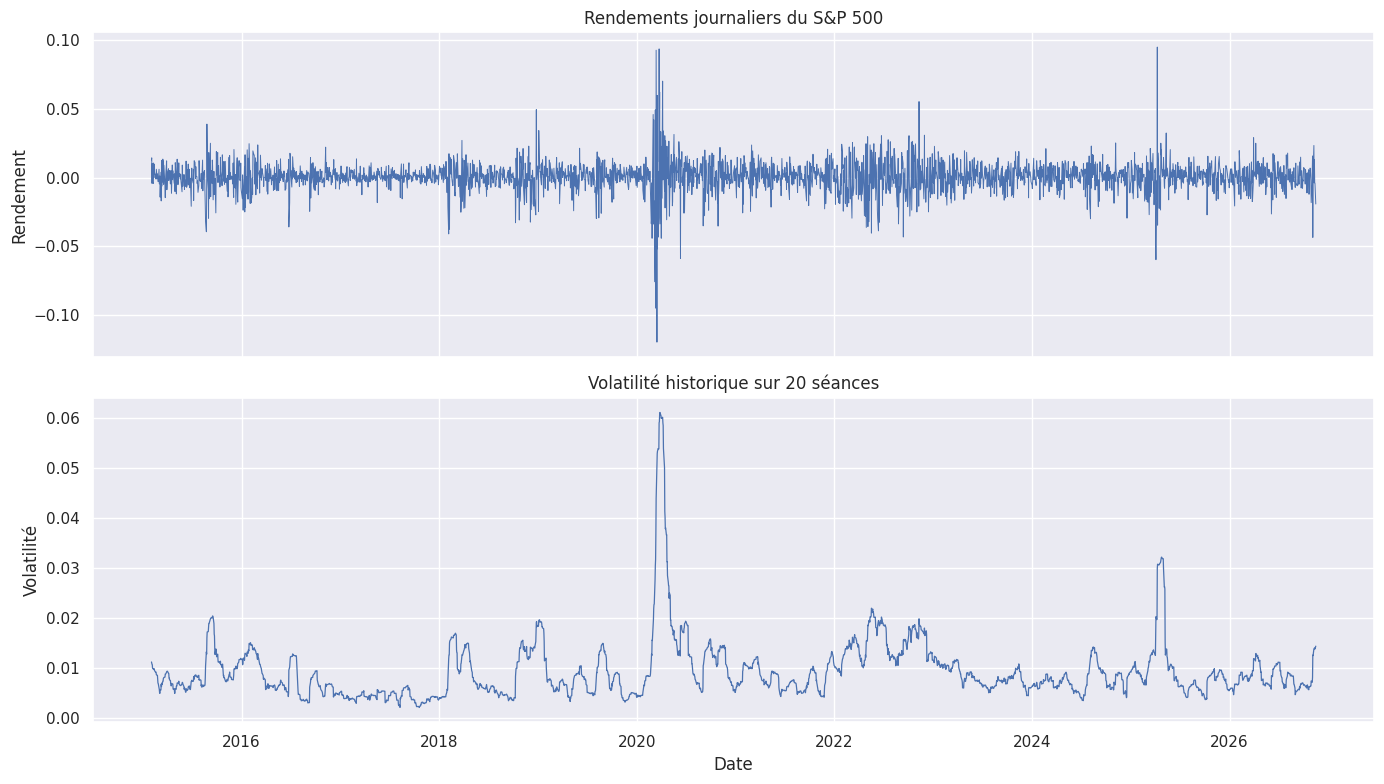

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(data.index, data["Return"], linewidth=0.7)
axes[0].set_title("Rendements journaliers du S&P 500")
axes[0].set_ylabel("Rendement")

axes[1].plot(data.index, data["Volatility"], linewidth=0.9)
axes[1].set_title("Volatilité historique sur 20 séances")
axes[1].set_ylabel("Volatilité")
axes[1].set_xlabel("Date")

plt.tight_layout()
plt.show()

La volatilité mesure l'intensité des fluctuations des rendements. Une volatilité élevée indique un marché plus agité, tandis qu'une volatilité faible correspond à des variations plus limitées.

## 7. Visualisation 3 – Momentum et drawdown

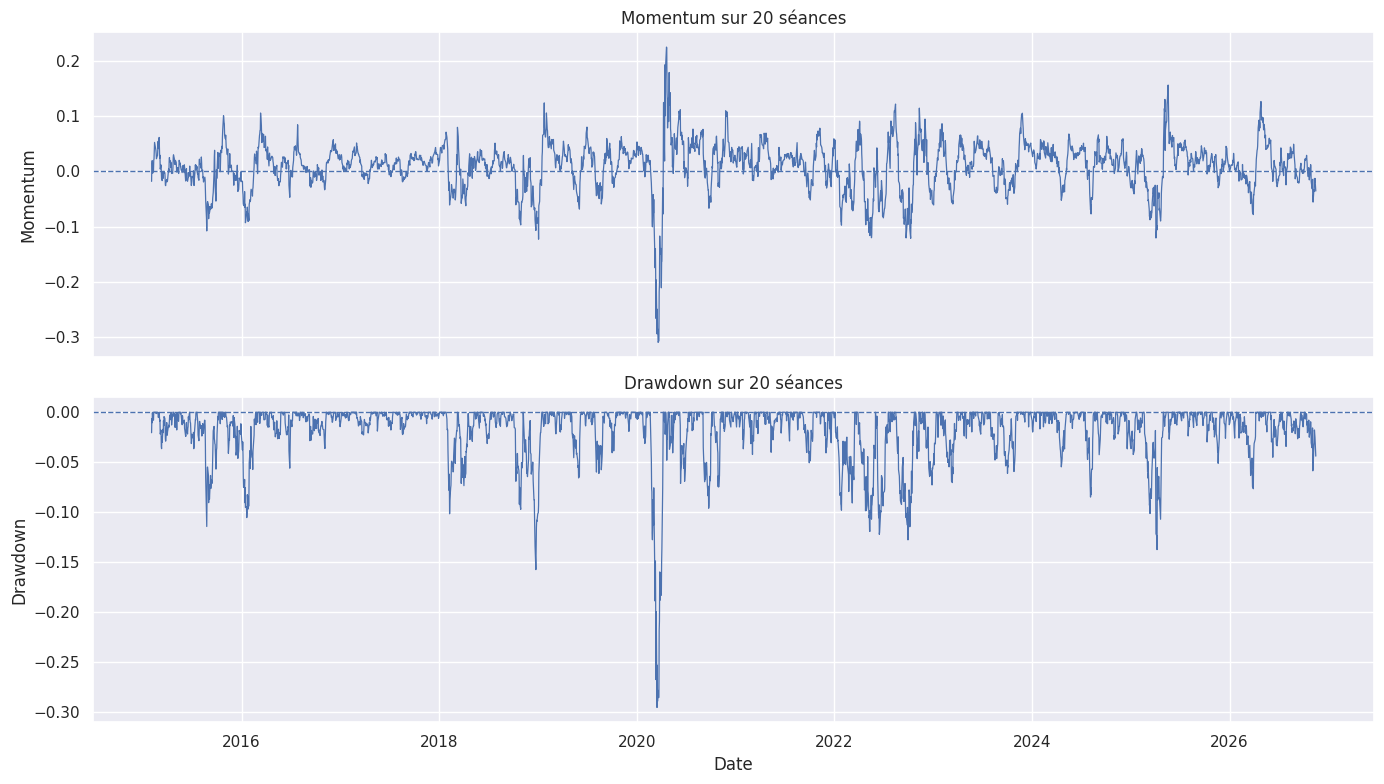

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(data.index, data["Momentum"], linewidth=0.9)
axes[0].axhline(0, linestyle="--", linewidth=1)
axes[0].set_title("Momentum sur 20 séances")
axes[0].set_ylabel("Momentum")

axes[1].plot(data.index, data["Drawdown"], linewidth=0.9)
axes[1].axhline(0, linestyle="--", linewidth=1)
axes[1].set_title("Drawdown sur 20 séances")
axes[1].set_ylabel("Drawdown")
axes[1].set_xlabel("Date")

plt.tight_layout()
plt.show()

Le momentum mesure la direction récente du marché : une valeur positive indique une progression sur la période considérée, et une valeur négative indique un recul.

Le drawdown mesure la baisse du prix par rapport au maximum récent. Des valeurs plus négatives signalent une baisse plus importante.

## 8. Préparation des variables pour le clustering

In [8]:
features = ["Return", "Volatility", "Momentum", "Drawdown"]
X = data[features].copy()

print("Variables retenues :", features)
print("Dimensions :", X.shape)
display(X.head())

Variables retenues : ['Return', 'Volatility', 'Momentum', 'Drawdown']
Dimensions : (2966, 4)


Price,Return,Volatility,Momentum,Drawdown
Date,,,,
2015-02-02,0.012962,0.011192,-0.018147,-0.020503
2015-02-03,0.014439,0.010899,0.014575,-0.006359
2015-02-04,-0.004156,0.010727,0.019425,-0.010489
2015-02-05,0.010291,0.010662,0.018076,-0.000305
2015-02-06,-0.003418,0.009919,-0.003234,-0.003722


## 9. Séparation chronologique des données

In [9]:
# Les observations les plus récentes sont conservées pour le test.
split_index = int(len(X) * 0.80)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

print("Période d'entraînement :", X_train.index.min().date(), "à", X_train.index.max().date())
print("Période de test :", X_test.index.min().date(), "à", X_test.index.max().date())
print("Taille entraînement :", X_train.shape)
print("Taille test :", X_test.shape)

Période d'entraînement : 2015-02-02 à 2024-07-05
Période de test : 2024-07-08 à 2026-11-16
Taille entraînement : (2372, 4)
Taille test : (594, 4)


## 10. Standardisation des variables

In [10]:
# Le scaler est ajusté uniquement sur la période d'entraînement.
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Standardisation terminée.")

Standardisation terminée.


## 11. Algorithme 1 – K-Means : choix du nombre de clusters

In [11]:
silhouette_scores = []
k_values = range(2, 7)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_train_scaled)

    score = silhouette_score(
        X_train_scaled,
        labels,
        sample_size=min(5000, len(X_train_scaled)),
        random_state=42
    )

    silhouette_scores.append(score)
    print(f"k = {k} | Silhouette Score = {score:.4f}")

k = 2 | Silhouette Score = 0.5331
k = 3 | Silhouette Score = 0.4782
k = 4 | Silhouette Score = 0.4334
k = 5 | Silhouette Score = 0.3307
k = 6 | Silhouette Score = 0.3344


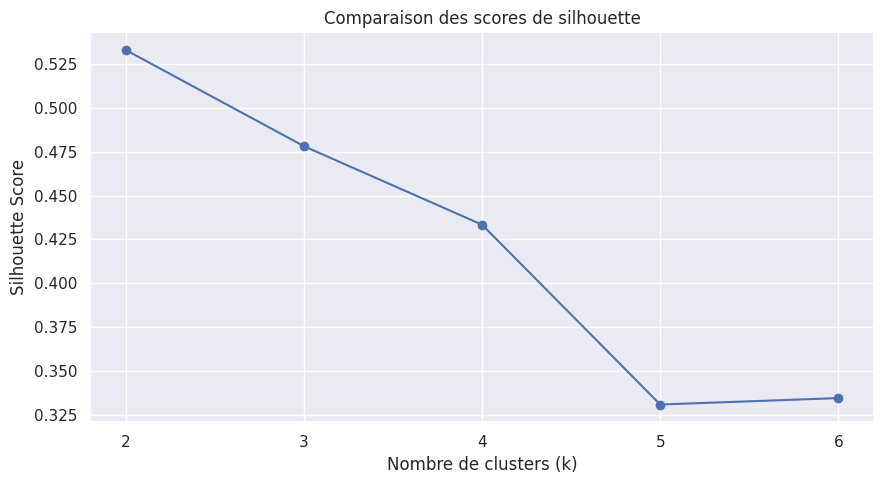

Nombre de clusters retenu : 2


In [12]:
plt.figure(figsize=(9, 5))
plt.plot(list(k_values), silhouette_scores, marker="o")
plt.title("Comparaison des scores de silhouette")
plt.xlabel("Nombre de clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

best_k = list(k_values)[int(np.argmax(silhouette_scores))]
print("Nombre de clusters retenu :", best_k)

## 12. Entraînement de K-Means et affectation des régimes

In [13]:
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
kmeans.fit(X_train_scaled)

train_labels = kmeans.predict(X_train_scaled)
test_labels = kmeans.predict(X_test_scaled)

data["Regime"] = np.concatenate([train_labels, test_labels])

print("Clustering terminé.")
display(data[["Close", "Return", "Volatility", "Momentum", "Drawdown", "Regime"]].head())

Clustering terminé.


Price,Close,Return,Volatility,Momentum,Drawdown,Regime
Date,,,,,,
2015-02-02,2020.849976,0.012962,0.011192,-0.018147,-0.020503,1
2015-02-03,2050.030029,0.014439,0.010899,0.014575,-0.006359,1
2015-02-04,2041.510010,-0.004156,0.010727,0.019425,-0.010489,1
2015-02-05,2062.520020,0.010291,0.010662,0.018076,-0.000305,1
2015-02-06,2055.469971,-0.003418,0.009919,-0.003234,-0.003722,1


## 13. Visualisation des régimes identifiés

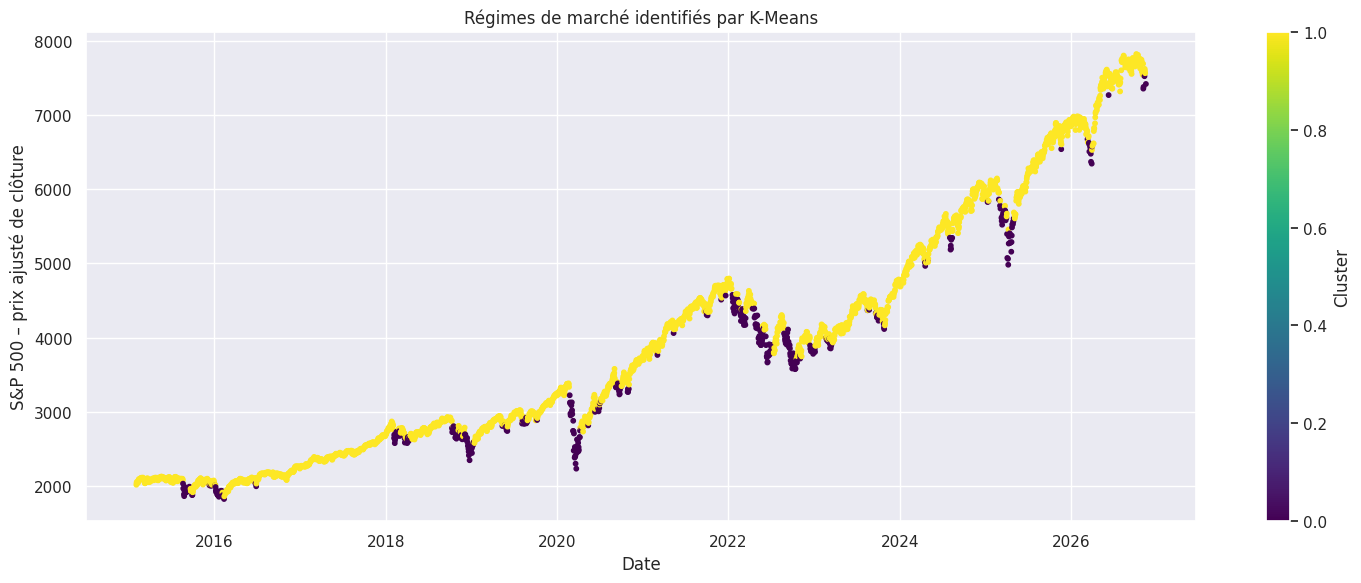

In [14]:
plt.figure(figsize=(15, 6))
scatter = plt.scatter(
    data.index,
    data["Close"],
    c=data["Regime"],
    cmap="viridis",
    s=10
)
plt.title("Régimes de marché identifiés par K-Means")
plt.xlabel("Date")
plt.ylabel("S&P 500 – prix ajusté de clôture")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()

## 14. Analyse et interprétation des clusters

In [15]:
regime_analysis = data.groupby("Regime")[features].agg(["mean", "std", "count"])
display(regime_analysis)

Price     Return                 Volatility                  Momentum  \
            mean       std count       mean       std count      mean   
Regime                                                                  
0      -0.005265  0.020562   453   0.016652  0.010034   453 -0.057664   
1       0.001545  0.007929  2513   0.007991  0.003926  2513  0.022081   

Price                   Drawdown                  
             std count      mean       std count  
Regime                                            
0       0.044398   453 -0.071782  0.040290   453  
1       0.029280  2513 -0.009322  0.011113  2513

In [16]:
# Tableau synthétique des moyennes par régime
regime_means = data.groupby("Regime")[features].mean()
display(regime_means)

print("\nNombre d'observations par régime :")
display(data["Regime"].value_counts().sort_index())

Price,Return,Volatility,Momentum,Drawdown
Regime,,,,
0,-0.005265,0.016652,-0.057664,-0.071782
1,0.001545,0.007991,0.022081,-0.009322



Nombre d'observations par régime :


,count
Regime,
0,453
1,2513


### Guide d'interprétation

Les numéros des clusters sont attribués automatiquement : le cluster 0 n'est pas nécessairement le marché haussier.

- Rendement moyen positif et momentum positif : régime potentiellement haussier.
- Rendement moyen négatif et drawdown négatif : régime potentiellement baissier.
- Volatilité élevée : régime plus instable.
- Volatilité faible et rendement proche de zéro : régime relativement calme.

Les noms définitifs des régimes doivent être attribués après examen des moyennes affichées dans le tableau précédent.

## 15. Limites de l'analyse

Cette première analyse utilise un seul indice et quatre indicateurs construits à partir de ses prix. Les clusters représentent des regroupements statistiques et ne garantissent pas une prévision des mouvements futurs. Les résultats dépendent également de la période étudiée, des variables sélectionnées et du nombre de clusters.

## 16. Conclusion

This project applies an unsupervised learning approach to historical S&P 500 data. Financial indicators such as daily returns, volatility, momentum and drawdown are used to identify groups of market observations with similar characteristics.

The identified clusters can help describe different market conditions. Further work will compare the clustering methods required by the course and examine the stability and financial interpretation of the resulting regimes.

## Important – Adaptation aux algorithmes du cours

K-Means est inclus comme première méthode de démonstration. Les algorithmes 17, 18, 19 et 20 demandés par le professeur ne sont pas encore intégrés, car leurs noms et leurs méthodes doivent être vérifiés à partir des pages du support de cours. Ajoutez ces méthodes dans une version ultérieure avant la remise finale.